# What If the Lap-19 Safety Car Had Never Come Out in Las Vegas?

Russell ran Soft → Medium and Antonelli ran Medium → Soft. Both stopped as the field slowed on lap 19. This notebook asks who each driver would have rejoined behind under green, and how much a later Soft stint would have needed to gain.

- **Observed timing** comes from the FIA and OpenF1 2026 race records.
- **Historical estimates** come from the 2025 Las Vegas green-stop sample.
- **Simulated outcomes** start from the pre-Safety-Car field. They estimate timing-line order and elapsed-time differences for declared scenarios.

Run the setup and execution commands in [README.md](README.md) from the project directory. The download manifest lists each input URL and SHA-256 hash. [FIA 2026 event timing](https://www.fia.com/events/fia-formula-one-world-championship/season-2026/las-vegas-grand-prix/eventtiming-information) · [OpenF1 documentation](https://openf1.org/docs/) · [Pirelli race report](https://press.pirelli.com/verstappen-wins-overtaking-spectacle-on-the-strip/)

In [1]:
from dataclasses import replace

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from vegas import plots, replay, timing
from vegas.sources import ROOT, RACE_2026, FP3_2026, RACE_2025, openf1, verify_cache

manifest = verify_cache()
output = ROOT / "outputs"
figures = ROOT / "figures"
for folder in (output, figures):
    folder.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 15)
pd.set_option("display.float_format", "{:,.3f}".format)
sessions = pd.DataFrame([
    openf1(key, "sessions")[0] for key in (RACE_2026, FP3_2026, RACE_2025)
])
assert sessions.circuit_short_name.eq("Las Vegas").all()
assert list(zip(sessions.year, sessions.session_name)) == [
    (2026, "Race"), (2026, "Practice 3"), (2025, "Race")
]
display(sessions[["session_key", "year", "session_name", "circuit_short_name"]])

,session_key,year,session_name,circuit_short_name
0,11420,2026,Race,Las Vegas
1,11415,2026,Practice 3,Las Vegas
2,9858,2025,Race,Las Vegas


## What to take from Buscombe’s figures

Ruth Buscombe’s attached *All on Red* briefing puts the pit exit after Turn 1, with little load before Turn 5. Her green-stop panel shows a Soft advantage of about three tenths over Medium in the first laps after stops across other 2026 races. Her race-pace panel shows almost no equal-age Soft advantage at cool Montréal and roughly 0.25–0.33 s/lap late at several warmer races. Her restart panel shows how much cooling under a VSC can change the first laps. Green-stop warm-up at Las Vegas remains an assumption, and the restart samples give context for its uncertainty.

The overtake map shows that the Strip into Turn 14 accounted for 95 of 158 historical passes. The race map links the gap at Turn 12 to passing chances. The article also reports final-sector gains in Vegas practice and qualifying with cars several seconds ahead. The replay therefore tracks who is ahead and allows a tow credit as well as a close-following cost. It uses finish-line gaps as a proximity proxy. Buscombe’s pass rates are measured at the straight and stay outside the model.

Pirelli identified laps 22–28 in its pre-race briefing and highlighted faster Soft warm-up. Its post-race report puts observed track temperature around 12 °C and describes both compounds as consistent. [Pirelli qualifying and strategy report](https://press.pirelli.com/antonelli-goes-all-in-sets-the-fastest-time-on-soft/) · [Pirelli race report](https://press.pirelli.com/verstappen-wins-overtaking-spectacle-on-the-strip/)

## 1. Observed 2026 timing

- **Own lap.** The FIA Lap Analysis and OpenF1 laps key on each car’s completed lap. The FIA History Chart columns key on the leader’s lap and can contain multiple crossings from a lapped car. Recover each car’s own lap by counting its chart entries, then verify against Lap Analysis. The official first lap duration comes from the History Chart. Lap Analysis prints the local time of the first crossing.
- **Pit-in and pit-out.** An official stop on lap (p) is an in-lap. The old set supplies that lap’s running compound. OpenF1 marks (p+1) as a pit-out lap and starts the next stint there. Tyre age at lap start is OpenF1’s age at stint start plus the completed laps in the stint. Tyre age at lap end adds one. FIA pit times of day and OpenF1 timestamps differ by roughly the pit-lane transit here. Car number and own lap are the join keys.
- **Gaps and neutralization.** Gaps use elapsed time to complete the same own lap. The race clock uses the OpenF1 start anchor and FIA lap durations. The Safety Car flag marks any overlap of an individual lap with the deployment-to-clear interval. The message’s lap number follows the leader. A car on an earlier own lap can already be under the Safety Car. Green includes local yellow flags outside full-course neutralizations. [FIA History Chart](https://www.fia.com/sites/default/files/2026_21_usa_f1_r0_timing_racehistorychart_v01.pdf) · [FIA Lap Analysis](https://www.fia.com/sites/default/files/2026_21_usa_f1_r0_timing_racelapanalysis_v01.pdf) · [FIA Pit Stop Summary](https://www.fia.com/sites/default/files/2026_21_usa_f1_r0_timing_racepitstopsummary_v01.pdf) · [FIA Race Control Messages](https://www.fia.com/sites/default/files/2026_21_usa_f1_r0_timing_raceracecontrolmessages_v01.pdf)

In [2]:
race, pits_2026, periods = timing.race_2026()
deployment = next(period for period in periods if period.kind == "SC")
assert (deployment.leader_lap_start, deployment.leader_lap_end) == (19, 25)
assert race.loc[race.lap.gt(1), "lap_time_delta_openf1_s"].abs().max() < 0.001
assert race.pit_out.eq(race.openf1_pit_out).all()

chart_gaps = race.loc[race.fia_history_gap_s.notna()]
assert (chart_gaps.gap_to_leader_s - chart_gaps.fia_history_gap_s).abs().max() < 0.001
lap18 = chart_gaps.loc[chart_gaps.lap.eq(18) & chart_gaps.fia_history_leader_lap.eq(18)]
clock_error = (lap18.openf1_clock_gap_s - lap18.fia_history_gap_s).abs().max()
openf1_laps = timing.load_laps(RACE_2026)
incomplete = openf1_laps.merge(race[timing.KEY], on=timing.KEY, how="left", indicator=True)
incomplete = incomplete.loc[incomplete["_merge"].eq("left_only")]
assert incomplete.openf1_lap_s.isna().all()

print(f"{len(race)} completed laps across {race.driver.nunique()} starters")
print(f"{int(race.lap.gt(1).sum())} lap durations after lap 1 match OpenF1")
print(f"{len(chart_gaps)} numeric FIA History Chart gaps agree with the elapsed race clock")
print(f"{len(lap18)} matching lap-18 crossings are within {clock_error:.3f} s of the OpenF1 timestamp-derived gaps")
print(f"{len(pits_2026)} pit-lane durations and stop laps agree")
print(f"Safety Car {deployment.start:%H:%M:%S}–{deployment.end:%H:%M:%S} UTC")
display(incomplete[timing.KEY + ["openf1_lap_s"]])
display(race.loc[
    race.driver.isin(["RUS", "ANT"]) & race.lap.isin([18, 19, 20]),
    ["driver", "lap", "lap_time_s", "compound", "tyre_age_start_laps", "pit_in", "pit_out", "track_status"],
])
race.to_csv(output / "2026_driver_laps.csv", index=False, float_format="%.3f")

985 completed laps across 21 starters
964 lap durations after lap 1 match OpenF1
942 numeric FIA History Chart gaps agree with the elapsed race clock
18 matching lap-18 crossings are within 0.208 s of the OpenF1 timestamp-derived gaps
23 pit-lane durations and stop laps agree
Safety Car 04:34:26–04:50:34 UTC


,driver_number,lap,openf1_lap_s
267,11,18,NaN
367,14,50,NaN
468,23,1,NaN
588,41,20,NaN


,driver,lap,lap_time_s,compound,tyre_age_start_laps,pit_in,pit_out,track_status
284,ANT,18,97.486,MEDIUM,17,False,False,GREEN
285,ANT,19,123.365,MEDIUM,18,True,False,SC
286,ANT,20,157.003,SOFT,3,False,True,SC
802,RUS,18,97.808,SOFT,20,False,False,GREEN
803,RUS,19,121.767,SOFT,21,True,False,SC
804,RUS,20,153.557,MEDIUM,0,False,True,SC


The FIA chart gives the first-lap duration for Lawson, whose OpenF1 lap time is missing. For the other 20 starters the OpenF1 first lap runs roughly 0.3–0.5 s longer than the official elapsed first lap. OpenF1 crossing timestamps are adequate for a check and too coarse to resolve Russell’s 0.007 s lap-18 gap. The FIA clock supplies the gaps used below.

## 2. Historical 2025 effective pit loss

For each official stop on own laps 20–29, subtract the sum of two baseline laps from the pit-in plus pit-out time.

```text
Effective loss = time[p] + time[p+1]
                 − median(time[p−3 : p−1])
                 − median(time[p+3 : p+5])
```

The indexed ranges are inclusive. In 2025 race control records two VSCs. All in-laps, out-laps and baseline laps in this sample fall outside those intervals. Compute the estimate from OpenF1 and independently from the FIA Lap Analysis, matching stops to the Formula 1 results. The official lane duration measures time between the lane limits. The two-lap estimate measures excess race time and already includes the out-lap’s warm-up and any traffic on the two measured laps. It also absorbs variation in the sampled references. [2025 FIA event timing](https://www.fia.com/events/fia-formula-one-world-championship/season-2025/las-vegas-grand-prix/eventtiming-information) · [Official Formula 1 pit-stop summary](https://www.formula1.com/en/results/2025/races/1274/las-vegas/pit-stop-summary)

In [3]:
historical, pits_2025 = timing.historical_pit_losses()
assert len(historical) == 11
assert np.allclose(historical.effective_loss_s, historical.fia_effective_loss_s, atol=0.001)
assert np.allclose(historical.official_lane_s, historical.openf1_lane_s, atol=0.001)
bounds = {
    "low": historical.effective_loss_s.min(),
    "median": historical.effective_loss_s.median(),
    "high": historical.effective_loss_s.max(),
}
display(historical[[
    "driver", "stop_lap", "compound_out", "pit_in_s", "pit_out_s",
    "pre_median_s", "post_median_s", "effective_loss_s", "fia_effective_loss_s", "official_lane_s",
]])
print(f"{len(historical)} stops: median {bounds['median']:.3f} s, range {bounds['low']:.3f}–{bounds['high']:.3f} s")
print(f"Median first flying lap vs settled baseline: {historical.first_flying_vs_settled_s.median():+.3f} s")
display(pits_2025.loc[
    pits_2025.lane_delta_openf1_s.abs().gt(0.001),
    ["driver", "lap", "official_lane_s", "openf1_lane_s", "lane_delta_openf1_s"],
])
historical.to_csv(output / "2025_green_pit_loss.csv", index=False, float_format="%.3f")

,driver,stop_lap,compound_out,pit_in_s,pit_out_s,pre_median_s,post_median_s,effective_loss_s,fia_effective_loss_s,official_lane_s
0,HAD,20,HARD,102.417,112.569,97.381,96.117,21.488,21.488,21.324
1,PIA,21,HARD,100.682,111.292,96.426,95.418,20.130,20.130,21.371
2,NOR,22,HARD,101.141,111.904,95.769,95.624,21.652,21.652,21.049
3,SAI,22,HARD,102.420,113.182,97.183,95.626,22.793,22.793,21.164
4,LEC,24,HARD,100.815,111.534,96.700,95.283,20.366,20.366,21.351
5,COL,25,MEDIUM,102.106,114.998,98.061,96.378,22.665,22.665,22.842
6,VER,25,HARD,100.284,111.173,95.807,95.098,20.552,20.552,21.708
7,OCO,27,HARD,101.965,113.271,97.240,95.351,22.645,22.645,22.389
8,TSU,27,MEDIUM,101.343,111.575,97.434,95.757,19.727,19.727,20.680
9,LAW,28,HARD,102.231,114.002,97.086,95.658,23.489,23.489,21.287


11 stops: median 21.652 s, range 19.727–24.918 s
Median first flying lap vs settled baseline: +0.258 s


,driver,lap,official_lane_s,openf1_lane_s,lane_delta_openf1_s
13,HUL,30,22.333,22.300,-0.033


The 11-stop estimate reproduces the pilot. The sample is Hard- and Medium-bound. Its first flying lap (p+2) is outside the effective loss and has a median excess of 0.258 s over the post-stop references. That is a scale for residual warm-up, with tyre age and race circumstances mixed in. The 2025 Hulkenberg lane-time discrepancy is on lap 30, outside the estimation sample.

## 3. Pilot check on the observed lap-18 gaps

Add the historical effective loss to one driver’s FIA gap, leave the other observed gaps in place, then sort the clocks. Rank and the gap to the car ahead are timing-line proxies for the earliest decision. The actual pit exit is after Turn 1. The number depends on who else pits and how the field moves before the exit.

In [4]:
pilot, observed_gaps = replay.observed_gap_rejoins(race, bounds)
display(pilot[[
    "driver", "historical_loss_case", "pit_loss_s", "position",
    "rejoin_behind", "gap_to_ahead_s", "rejoin_ahead_of", "gap_to_behind_s",
]])
stay_ahead_of_bearman = (observed_gaps["BEA"] - observed_gaps.loc[list(replay.TARGETS)]).rename(
    "loss_ceiling_to_stay_ahead_of_BEA_s"
)
display(stay_ahead_of_bearman.to_frame())
pilot.to_csv(output / "lap18_rejoin.csv", index=False, float_format="%.3f")

,driver,historical_loss_case,pit_loss_s,position,rejoin_behind,gap_to_ahead_s,rejoin_ahead_of,gap_to_behind_s
0,VER,low,19.727,14,HUL,2.678,BEA,2.138
1,VER,median,21.652,14,HUL,4.603,BEA,0.213
2,VER,high,24.918,15,BEA,3.053,ALO,5.130
3,RUS,low,19.727,14,HUL,2.685,BEA,2.131
4,RUS,median,21.652,14,HUL,4.610,BEA,0.206
5,RUS,high,24.918,15,BEA,3.060,ALO,5.123
6,ANT,low,19.727,14,HUL,3.884,BEA,0.932
7,ANT,median,21.652,15,BEA,0.993,ALO,7.190
8,ANT,high,24.918,15,BEA,4.259,ALO,3.924


,loss_ceiling_to_stay_ahead_of_BEA_s
driver,
VER,21.865
RUS,21.858
ANT,20.659


At the median, Verstappen and Russell rejoin behind Hülkenberg with a gap of about 4.6 s. Bearman is only 0.213 s behind Verstappen’s projected line crossing and 0.206 s behind Russell’s. Antonelli exits the timing-line proxy 0.993 s behind Bearman. The full historical range puts each car at P14 or P15. The gaps imply different chances to pick up a tow or become stuck following a slower car.

## 4. Replay the pit window

Start with frozen gaps. The alternative field takes each car’s median green pace on its available laps 14–18, subtracts Verstappen’s median, and applies 0%, 50% or 100% of that difference per projected lap. The half-pace case is the central scenario. At lap 28 this changes where the gaps are, even when the median rejoin rank holds.

Use only crossings up to own lap 18 and before the deployment timestamp. Pérez lacks a completed lap 18. Câmara completed it under the Safety Car. Give both a projected green lap 18 from their own lap 17 finish and recent pace. Lawson started a lap down and stays outside these lead-lap rankings. Albon has no completed laps. The green-running baseline keeps every car active at the anchor in the field. Outside the stops declared in each scenario, the other cars stay on their projected clocks for the traffic calculation.

,lap,lap18_basis,lap18_clock_s,compound,recent_pace_s,pace_offset_s
driver,,,,,,
VER,18,Observed crossing,0.000,SOFT,98.195,0.000
RUS,18,Observed crossing,0.007,SOFT,98.044,-0.151
HAD,18,Observed crossing,0.540,SOFT,98.075,-0.120
ANT,18,Observed crossing,1.206,MEDIUM,97.961,-0.234
LIN,18,Observed crossing,2.754,SOFT,98.135,-0.060
GAS,18,Observed crossing,3.579,SOFT,98.588,0.393
HAM,18,Observed crossing,4.513,SOFT,97.905,-0.290
NOR,18,Observed crossing,4.767,SOFT,97.578,-0.617
PIA,18,Observed crossing,4.850,SOFT,97.541,-0.654


,pit_lap,driver,spread,position,rejoin_behind,gap_to_ahead_s,gap_to_behind_s
34,22,ANT,0.000,15,BEA,0.993,4.732
124,22,ANT,0.500,14,HUL,4.969,1.383
214,22,ANT,1.000,14,HUL,4.129,3.759
31,22,RUS,0.000,14,HUL,4.610,0.206
121,22,RUS,0.500,14,HUL,3.936,2.416
211,22,RUS,1.000,14,HUL,3.262,4.626
28,22,VER,0.000,14,HUL,4.603,0.213
118,22,VER,0.500,14,HUL,4.231,2.121
208,22,VER,1.000,14,HUL,3.859,4.029
88,28,ANT,0.000,15,BEA,0.993,4.732


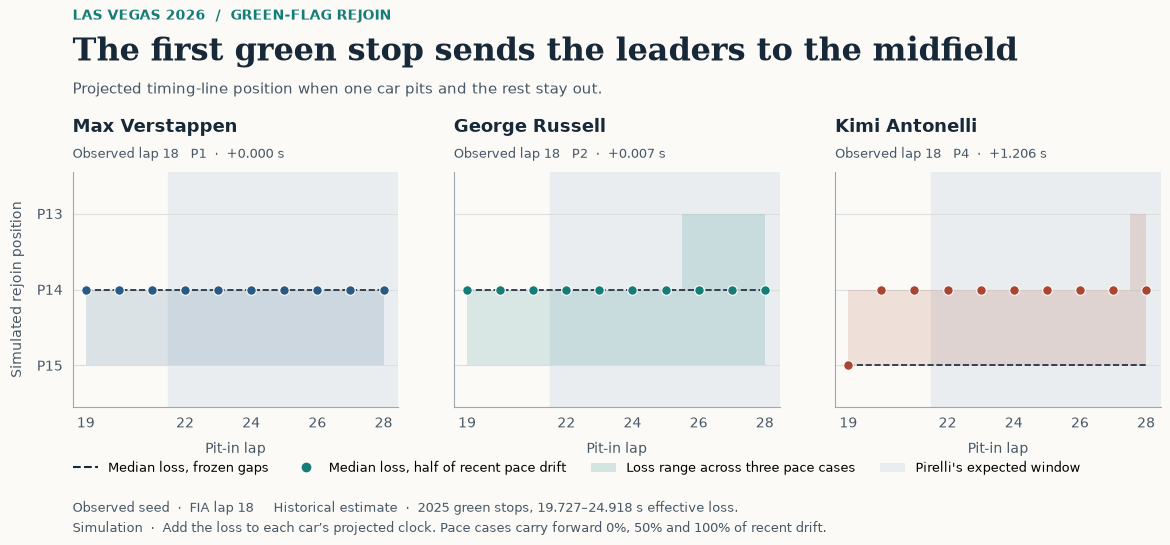

In [5]:
field = replay.seed_field(race, deployment.start)
assert field.lap_end_utc.lt(deployment.start).all()
assert len(field.loc[field.included]) == 20
display(field[[
    "lap", "lap18_basis", "lap18_clock_s", "compound", "recent_pace_s", "pace_offset_s",
]])
projections = replay.projected_rejoins(field, bounds)
display(projections.loc[
    projections.historical_loss_case.eq("median") & projections.pit_lap.isin([22, 28]),
    ["pit_lap", "driver", "spread", "position", "rejoin_behind", "gap_to_ahead_s", "gap_to_behind_s"],
].sort_values(["pit_lap", "driver", "spread"]))
field.to_csv(output / "replay_start.csv", float_format="%.3f")
projections.to_csv(output / "projected_rejoins.csv", index=False, float_format="%.3f")

fig = plots.rejoin_figure(projections, observed_gaps, bounds)
fig.savefig(figures / "01_rejoin_position.png", dpi=220, facecolor=fig.get_facecolor())
plt.show()
plt.close(fig)

## 5. What the local data can estimate

**FP3 warm-up proxy.** For each new Soft or Medium stint, keep FIA-matched timed laps outside pit-in, pit-out and recorded deletions. Take the first two within 2 s of the set’s fastest valid lap. Require at least three valid laps in the stint, first push by tyre age four, and no more than four lap numbers between pushes. The second-minus-first change mixes warm-up, cooldowns, fuel and track evolution. It informs the scale of early-lap variation, while leaving the race out-lap cost uncertain.

**Race degradation proxy.** On each first stint, estimate the median of the pairwise lap-time slopes on green laps 6–18. The second estimate removes the time of the same-lap field median before taking the slope. It measures relative pace drift and still mixes traffic, fuel, track evolution and tyres. Only two Medium starters have enough lead-lap running. Use a range for degradation on each compound. [FIA FP3 lap times](https://www.fia.com/sites/default/files/2026_21_usa_f1_p3_timing_thirdpracticesessionlaptimes_v01.pdf)

In [6]:
fp3 = timing.fp3_2026()
pairs = timing.fp3_push_pairs(fp3)
trends = replay.observed_stint_trends(race, deployment.start)
display(pairs.groupby("compound").second_minus_first_s.agg(["size", "median", "min", "max"]))
display(trends.groupby("compound")[["raw_s_per_lap", "relative_s_per_lap"]].agg(["size", "median", "min", "max"]))
pairs.to_csv(output / "fp3_push_pairs.csv", index=False, float_format="%.3f")
trends.to_csv(output / "2026_pre_sc_pace_trends.csv", index=False, float_format="%.3f")

,size,median,min,max
compound,,,,
MEDIUM,8,-0.440,-1.311,-0.142
SOFT,38,-0.437,-1.652,1.222


raw_s_per_lap                      relative_s_per_lap                \
                  size median    min    max               size median    min   
compound                                                                       
MEDIUM               2 -0.072 -0.101 -0.043                  2  0.028 -0.011   
SOFT                18 -0.068 -0.172 -0.002                 18  0.016 -0.081   

                
           max  
compound        
MEDIUM   0.066  
SOFT     0.071

## 6. Same-car strategy scenarios

Every plan starts from Russell’s FIA lap-18 clock and recent pace. Hold the car constant. Use a three-lap-used Soft like Russell’s first set and assume a fresh Medium for both orders. Add tyre pace relative to staying out on the opening Soft. Pace depends on set age and a Soft advantage at equal age. Allow the Soft advantage to change from lap 26 onward. A common track and fuel trend cancels in the matched-car time comparison.

For an earlier or later stop, book the historical effective charge at the rejoin proxy. Replace its assumed embedded warm-up by adding only the difference between the 2026 compound’s out-lap term and the 2025 reference. Apply an extra residual on the first flying lap (p+2), which lies outside the two-lap estimate. The separate out-lap component is unidentified in the 2025 sample.

For the first five flying laps, price proximity to the nearest car ahead from the projected preceding crossing. Inside 1 s, add a close-following cost. The tow credit is at full strength through 2 s and fades linearly to zero at 6 s. The signed sum can favor a car with traffic ahead. The proximity calculation uses the clean timing paths. It offers a repeatable traffic estimate in this first replay. Individual overtakes, battery deployment and team pit-stack delays require a finer model.

Compare laps 19, 22 and 28, and stay out through lap 28 as a checkpoint. In the cover case, Verstappen pits on lap 23 in response to the reference car’s lap-22 stop. Compare the two modeled clocks after both out-laps. Only one-stop strategies receive a lap-50 comparison. The remaining field stays out in the pit-window rankings.

In [7]:
settings = replay.Parameters(pit_loss_s=bounds["median"])
scenarios = replay.strategy_scenarios(field, settings)
display(scenarios[[
    "order", "pit_lap", "rival_pit_lap", "position", "rejoin_behind", "gap_to_ahead_s",
    "lap28_position_proxy", "net_traffic_s", "versus_rival_after_both_outlaps_s",
    "race_time_delta_vs_early_medium_s",
]])
scenarios.to_csv(output / "strategy_scenarios.csv", index=False, float_format="%.3f")

,order,pit_lap,rival_pit_lap,position,rejoin_behind,gap_to_ahead_s,lap28_position_proxy,net_traffic_s,versus_rival_after_both_outlaps_s,race_time_delta_vs_early_medium_s
0,Soft → Medium,19.000,NaN,14.000,HUL,4.591,13,-0.602,NaN,-0.849
1,Soft → Medium,22.000,NaN,14.000,HUL,4.086,13,-0.173,NaN,0.000
2,Soft → Medium,28.000,NaN,14.000,HUL,3.075,14,-0.157,NaN,1.576
3,Soft → Medium,NaN,NaN,NaN,NaN,NaN,1,0.000,NaN,NaN
4,Soft → Medium,22.000,23.000,14.000,HUL,4.086,12,-0.173,-0.895,0.000
5,Medium → Soft,19.000,NaN,14.000,HUL,3.736,13,-0.190,NaN,2.473
6,Medium → Soft,22.000,NaN,14.000,HUL,2.406,13,-0.126,NaN,1.038
7,Medium → Soft,28.000,NaN,13.000,SAI,4.050,13,0.292,NaN,-0.105
8,Medium → Soft,NaN,NaN,NaN,NaN,NaN,1,0.000,NaN,NaN
9,Medium → Soft,22.000,23.000,14.000,HUL,2.406,12,-0.126,-2.674,1.038


A negative lap-50 delta favors the listed plan over Soft → Medium on lap 22. A negative rival gap means the reference is ahead at the end of lap 24 in the cover scenario. Both comparisons are simulated. Other cars’ stops could change the result by clearing the cars ahead or moving a rival into the same queue.

### Sensitivity assumptions

| Input | Central setting | Range and basis |
| --- | ---: | --- |
| Historical effective pit loss | 21.652 s | 19.727–24.918 s, full 2025 sample extrema |
| Fraction of recent relative pace carried forward | 0.50 | 0–1, frozen gaps through full 2026 drift |
| Warm-up embedded in the 2025 measure | 0.60 s | 0–1.20 s, accounting assumption |
| Soft / Medium out-lap warm-up | 0.15 / 0.75 s | Soft 0–0.65 s and Medium 0.20–1.40 s. FP3, Buscombe’s green-stop context, and Pirelli suggest testing the quicker Soft and a broad cold-track range |
| First flying lap warm-up | 35% of out-lap term | 0–65%. The historical first-flying-lap median excess gives a scale |
| Soft / Medium degradation | 0.025 / 0.015 s per lap of age | Soft 0–0.06 and Medium 0–0.05. Pre-SC trends and FP3 support a low-wear base case with broad uncertainty |
| Soft advantage at equal age, before / after lap 25 | 0.00 / 0.12 s/lap | Early −0.10 to +0.20 and late −0.10 to +0.45. Covers near parity at cool Montréal and the faster Soft in warmer-race context |
| Soft starting set age | 3 laps | 0–3 laps to test the value of having a new set |
| First-stint Medium graining from age 20 | 0 s/lap | 0–0.45 s/lap, stress case for extending the opening Medium |
| Close-following penalty / peak tow credit | 0.50 / 0.15 s per lap | 0–0.90 and 0–0.30. Buscombe’s sector figures motivate testing a tow at multiple gaps. The size of the full-lap effect is assumed |

The sweep changes one input at a time around the central case. It shows reversals and leaves joint probabilities unspecified.

In [8]:
effects = replay.sensitivity(field, settings, bounds)
display(effects.loc[~effects.central_case, [
    "parameter", "value", "early_medium_rejoin", "late_soft_rejoin",
    "extra_traffic_late_s", "late_soft_gain_s", "required_late_soft_adv_s_per_lap",
]])
effects.to_csv(output / "sensitivity.csv", index=False, float_format="%.4f")

,parameter,value,early_medium_rejoin,late_soft_rejoin,extra_traffic_late_s,late_soft_gain_s,required_late_soft_adv_s_per_lap
0,pit_loss_s,19.727,14,13,0.098,0.472,0.099
2,pit_loss_s,24.918,15,14,-0.012,0.582,0.094
3,field_spread,0.000,14,14,1.063,-0.493,0.142
5,field_spread,1.000,14,13,0.230,0.340,0.105
6,ref_out_warm_s,0.000,14,14,0.445,0.125,0.114
8,ref_out_warm_s,1.200,14,13,0.536,0.034,0.118
9,soft_out_warm_s,0.000,14,13,0.457,0.316,0.106
11,soft_out_warm_s,0.650,14,14,0.009,-0.114,0.125
12,medium_out_warm_s,0.200,14,13,0.433,-0.606,0.148
14,medium_out_warm_s,1.400,14,13,0.873,0.575,0.094


## 7. How fast does the late Soft need to be?

The later plan pays off if its clean elapsed-time gain is greater than its extra net traffic cost relative to boxing for Mediums on lap 22. The common historical pit charge cancels as a direct time difference. Changing it can still put either car into a different queue. The warmed Soft pace needed is the remaining time deficit divided by the late laps on Softs, after accounting for the first stint, set ages, degradation and warm-up. In this figure both plans make one green stop.

,late_pit_lap,soft_laps_in_low_fuel_phase,extra_net_traffic_s,required_soft_adv_s_per_lap
0,26,24,0.000,0.106
1,26,24,2.000,0.190
2,26,24,4.000,0.273
3,28,22,0.000,0.094
4,28,22,2.000,0.185
5,28,22,4.000,0.276


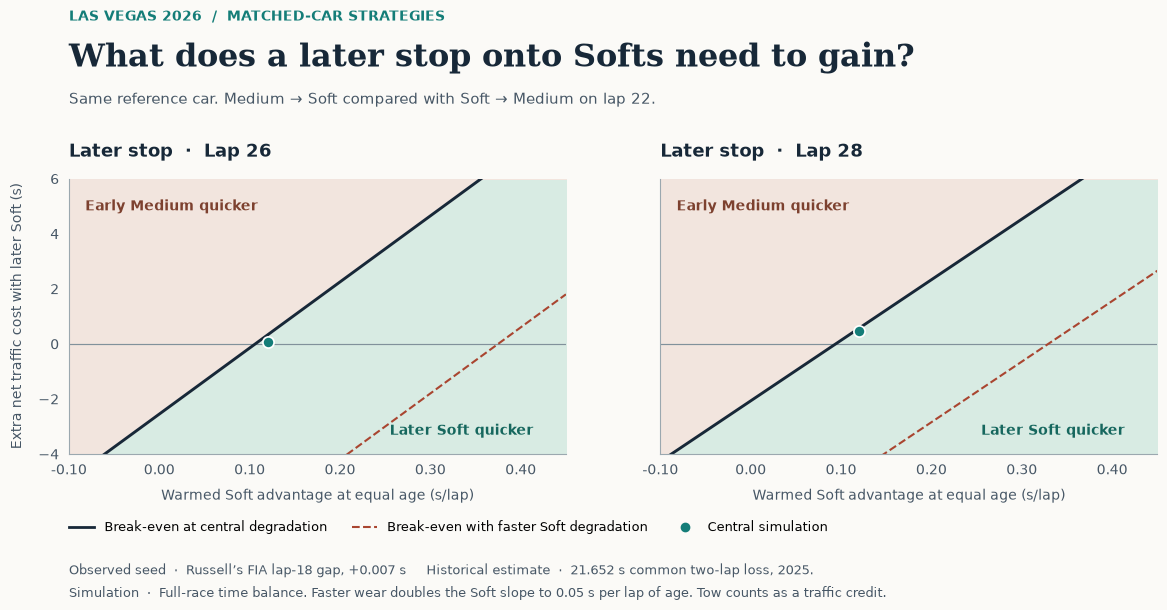

In [9]:
thresholds = pd.DataFrame([
    {
        "late_pit_lap": lap,
        "soft_laps_in_low_fuel_phase": replay.RACE_LAPS - lap,
        "extra_net_traffic_s": extra,
        "required_soft_adv_s_per_lap": replay.break_even(field, settings, lap, extra),
    }
    for lap in (26, 28) for extra in (0.0, 2.0, 4.0)
])
for row in thresholds.itertuples(index=False):
    at_threshold = replace(settings, late_soft_adv_s=row.required_soft_adv_s_per_lap)
    assert np.isclose(replay.clean_late_gain(field, at_threshold, row.late_pit_lap), row.extra_net_traffic_s)

display(thresholds)
thresholds.to_csv(output / "break_even.csv", index=False, float_format="%.4f")

fig = plots.break_even_figure(field, settings)
fig.savefig(figures / "02_late_soft_break_even.png", dpi=220, facecolor=fig.get_facecolor())
plt.show()
plt.close(fig)

## 8. Stress test Verstappen’s cover and the rest of the pit window

The joint replay puts Russell on Mediums on lap 22 and Antonelli on Softs on lap 28. Each starts from his own observed lap-18 gap, recent pace and opening-set age. Verstappen either stays out or covers on lap 22, 23 or 24. Test each timing with the other front-runners staying out and with a declared seven-car pit wave. The wave is a hypothetical schedule for the other lap-18 top-ten drivers, with one Soft-to-Medium stop per lap. Hadjar stops after Verstappen’s possible cover laps.

A rejoin is the projected order at the finish line of the pit-in lap, where the model books the effective two-lap stop cost. The rank includes all cars stopping on that lap and traffic already incurred by previous stoppers. The cars share the historical pit charge before compound warm-up adjustments. The traffic model uses the cars’ projected nearest neighbours and adds the existing close-following and tow terms on the first five flying laps.

In [10]:
pit_wave = {"NOR": 22, "PIA": 23, "GAS": 24, "HAD": 25, "LIN": 26, "HAM": 27, "LEC": 28}
stress = replay.cover_stress_test(field, settings, pit_wave)

# The one-lap cover should reproduce the original scripted result before Antonelli's stop.
original_cover = scenarios.loc[
    scenarios.order.eq("Soft → Medium") & scenarios.rival_pit_lap.eq(23),
    "versus_rival_after_both_outlaps_s",
].iat[0]
replayed_cover = stress.loc[
    ~stress.front_runner_pit_wave & stress.verstappen_pit_lap.eq(23),
    "russell_lead_after_both_out_s",
].iat[0]
assert np.isclose(replayed_cover, -original_cover)
assert np.allclose(
    stress.loc[stress.verstappen_pit_lap.eq(22), "russell_stop_gain_vs_both_staying_out_s"], 0.0
)

cover_labels = {22: "Same lap (22)", 23: "One lap later (23)", 24: "Two laps later (24)"}
field_labels = {False: "Field holds", True: "Pit wave"}
last_names = pd.DataFrame(openf1(RACE_2026, "drivers")).set_index("name_acronym").last_name

display(pd.DataFrame({"Wave stop lap": pit_wave.values(), "Driver": last_names.loc[list(pit_wave)].to_list()}))
results = pd.DataFrame({
    "Other front-runners": stress.front_runner_pit_wave.map(field_labels),
    "Verstappen": stress.verstappen_pit_lap.map(cover_labels).fillna("Stays out"),
})
for driver, lap in [("russell", 22), ("antonelli", 28)]:
    results[f"{driver.title()} rejoin (L{lap})"] = [
        f"P{position} · {last_names.at[car]} +{gap:.2f} s"
        for position, car, gap in zip(
            stress[f"{driver}_position"], stress[f"{driver}_rejoin_behind"], stress[f"{driver}_gap_to_ahead_s"],
            strict=True,
        )
    ]
display(results)
stress.to_csv(output / "cover_stress_test.csv", index=False, float_format="%.4f")

,Wave stop lap,Driver
0,22,Norris
1,23,Piastri
2,24,Gasly
3,25,Hadjar
4,26,Lindblad
5,27,Hamilton
6,28,Leclerc


,Other front-runners,Verstappen,Russell rejoin (L22),Antonelli rejoin (L28)
0,Field holds,Stays out,P14 · Hulkenberg +4.09 s,P14 · Hulkenberg +3.26 s
1,Field holds,Same lap (22),P13 · Hulkenberg +4.09 s,P14 · Verstappen +0.96 s
2,Field holds,One lap later (23),P14 · Hulkenberg +4.09 s,P14 · Verstappen +2.26 s
3,Field holds,Two laps later (24),P14 · Hulkenberg +4.09 s,P14 · Verstappen +2.02 s
4,Pit wave,Stays out,P13 · Hulkenberg +4.09 s,P8 · Hadjar +1.20 s
5,Pit wave,Same lap (22),P12 · Hulkenberg +4.09 s,P8 · Verstappen +0.96 s
6,Pit wave,One lap later (23),P13 · Hulkenberg +4.09 s,P8 · Hadjar +1.23 s
7,Pit wave,Two laps later (24),P13 · Hulkenberg +4.09 s,P8 · Hadjar +0.23 s


### Measure the payoff

- **Russell versus Verstappen.** Check the gap once both cars have completed their out-laps. Subtract their projected gap at that same lap if both had stayed out to find the gain due to stopping. This removes the relative pace drift already in the starting projection. Also check the lead at lap 28, when every tested cover is through its out-lap.
- **Antonelli’s wait.** Compare his lap-28 Soft stop with taking the Soft on lap 23, one lap after Russell, while the rest of that schedule runs as declared. Lap 23 is the earliest alternative here that avoids a Mercedes double-stack.
- **Original matched-car comparison.** Compare lap-28 Medium → Soft with lap-22 Soft → Medium using Russell’s clock and pace for both. Run a single Mercedes stop in each branch and keep the other teams’ declared stop laps fixed. This isolates the strategy comparison from the two-driver payoff. A positive Soft or wait gain means the later stop is faster at lap 50.

In [11]:
payoffs = results[["Other front-runners", "Verstappen"]].copy()
payoffs["Both out by lap"] = stress.both_out_lap.astype("Int64")
payoffs["Russell lead after both out (s)"] = stress.russell_lead_after_both_out_s
payoffs["Russell gain from stop timing (s)"] = stress.russell_stop_gain_vs_both_staying_out_s
payoffs["Russell lead at lap 28 (s)"] = stress.russell_lead_at_lap_28_s
payoffs["Antonelli wait gain (s)"] = stress.antonelli_wait_gain_s
payoffs["Matched late Soft gain (s)"] = stress.matched_late_soft_gain_s
display(payoffs.astype(object).where(payoffs.notna(), "—"))

,Other front-runners,Verstappen,Both out by lap,Russell lead after both out (s),Russell gain from stop timing (s),Russell lead at lap 28 (s),Antonelli wait gain (s),Matched late Soft gain (s)
0,Field holds,Stays out,—,—,—,-17.603,0.118,0.105
1,Field holds,Same lap (22),23,0.371,0.000,2.671,1.618,0.105
2,Field holds,One lap later (23),24,0.895,0.449,1.371,2.634,0.105
3,Field holds,Two laps later (24),25,1.712,1.191,1.611,0.640,0.105
4,Pit wave,Stays out,—,—,—,-17.603,-0.860,0.105
5,Pit wave,Same lap (22),23,0.371,0.000,2.671,0.640,0.105
6,Pit wave,One lap later (23),24,0.895,0.449,1.371,1.640,0.105
7,Pit wave,Two laps later (24),25,1.712,1.191,1.611,-0.360,0.105


### Check the pit-loss and field-spread range

Repeat each schedule at the three historical pit-loss values and at zero, half and full recent pace drift. This changes the common pit charge and the gaps around each stop. Tyre and traffic parameters use their central settings, with wider individual sensitivity in Section 6.

In [12]:
stress_grid = pd.concat([
    replay.cover_stress_test(
        field, replace(settings, pit_loss_s=loss, field_spread=spread), pit_wave,
    ).assign(historical_loss_case=loss_case, pit_loss_s=loss, field_spread=spread)
    for loss_case, loss in bounds.items()
    for spread in (0.0, 0.5, 1.0)
], ignore_index=True)

intervals = []
for (wave_active, cover), group in stress_grid.groupby(
    ["front_runner_pit_wave", "verstappen_pit_lap"], dropna=False, sort=False,
):
    interval = {"Other front-runners": field_labels[wave_active], "Verstappen": cover_labels.get(cover, "Stays out")}
    for driver in ("russell", "antonelli"):
        ranks = group[f"{driver}_position"]
        interval[f"{driver.title()} rejoin range"] = f"P{ranks.min()}–P{ranks.max()}"
    for name, key in [
        ("Stop timing gain (s)", "russell_stop_gain_vs_both_staying_out_s"),
        ("Antonelli wait gain (s)", "antonelli_wait_gain_s"),
        ("Matched late Soft gain (s)", "matched_late_soft_gain_s"),
    ]:
        values = group[key].dropna()
        interval[name] = f"{values.min():+.3f} to {values.max():+.3f}" if len(values) else "—"
    intervals.append(interval)
display(pd.DataFrame(intervals))
stress_grid.to_csv(output / "cover_stress_sensitivity.csv", index=False, float_format="%.4f")

,Other front-runners,Verstappen,Russell rejoin range,Antonelli rejoin range,Stop timing gain (s),Antonelli wait gain (s),Matched late Soft gain (s)
0,Field holds,Stays out,P14–P15,P13–P15,—,+0.118 to +1.540,-0.549 to +1.345
1,Field holds,Same lap (22),P13–P15,P13–P15,+0.000 to +0.000,+1.047 to +2.640,-0.549 to +2.909
2,Field holds,One lap later (23),P14–P15,P13–P15,-0.003 to +0.497,-0.860 to +3.588,-0.549 to +1.345
3,Field holds,Two laps later (24),P14–P15,P12–P15,+0.702 to +1.260,-0.860 to +3.081,-0.549 to +1.345
4,Pit wave,Stays out,P13–P14,P8–P10,—,-0.860 to +1.140,-1.549 to +1.345
5,Pit wave,Same lap (22),P12–P14,P8–P10,+0.000 to +0.000,+0.144 to +2.140,-1.549 to +2.909
6,Pit wave,One lap later (23),P13–P14,P8–P9,-0.003 to +0.497,+0.140 to +2.640,-1.549 to +1.345
7,Pit wave,Two laps later (24),P13–P14,P7–P9,+0.702 to +1.260,-0.360 to +2.140,-1.549 to +1.345


### What survives the stress test

- **Russell still gives up track position.** He rejoins P12–P14 in the central cases and P12–P15 over the grid. Hülkenberg is 4.09 s ahead in every central case, even as the rank improves when others pit.
- **A delayed cover can reward the first stop.** The same-lap cover gives zero stop-induced gain. The one-lap cover’s original 0.90 s lead includes 0.45 s from the projected pace difference. The stop-induced part ranges from −0.003 to +0.497 s. A two-lap delay gives a positive stop-induced gain of 0.70–1.26 s throughout this grid. Russell is ahead once both cars are out and at lap 28 in all tested delayed-cover cases.
- **The later Soft needs a usable gap.** The pit wave improves Antonelli’s central rejoin from P14 to P8. With a two-lap cover, it changes the car ahead from Verstappen at 2.02 s to Hadjar at 0.23 s. Waiting then goes from gaining 0.64 s to losing 0.36 s against Antonelli’s lap-23 stop. The original matched-car late Soft gain stays near 0.10 s in every central cover and wave case. It ranges from a 1.55 s loss to a 2.91 s gain over the grid.

## Article takeaway

**The Safety Car spared Mercedes the green-flag first-stopper trade.** At the historical median loss, Russell’s green-stop proxy is P14, only 0.206 s ahead of Bearman. Antonelli’s is P15, within a second behind Bearman. A small change in pit loss or the field’s spread changes who sets the pace ahead, how soon the new tyre can be used, and where the tow is available.

The same-car break-even needs about 0.094 s/lap of late warmed Soft advantage with equal traffic, 0.115 s/lap with the central traffic difference, and 0.185 s/lap with two extra seconds in traffic. Quicker Medium warm-up, heavier Soft wear, graining on the opening Medium, or fewer gaps in the field can flip the result.

The strongest angle is the first stopper’s trade. Russell could have bought an early read on Medium warm-up and forced Verstappen to decide how long to wait. Antonelli could keep the option to take the Soft later. A group of early stops can open positions on the timing screen and still leave him close behind a car on fresher tyres.